# Compare SHAP and LIME explanations by performing an in-depth statistical correlation analysis, manually quantifying consistency across methods, and identifying limitations in each approach for different feature types.

In [1]:
!pip install shap lime scipy


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import pearsonr, spearmanr, kendalltau

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [4]:
df = pd.read_csv("heart.csv")

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed!")
print("Features:", len(feature_names))


Preprocessing completed!
Features: 20


In [5]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_processed, y_train)

print("Training completed!")
print("Test Accuracy:", model.score(X_test_processed, y_test))

Training completed!
Test Accuracy: 0.9021739130434783


# Generate SHAP explanations

In [6]:
shap_explainer = shap.TreeExplainer(model)

shap_values = shap_explainer.shap_values(
    X_test_processed
)

if isinstance(shap_values, list):
    shap_positive = shap_values[1]

elif len(shap_values.shape) == 3:
    shap_positive = shap_values[:, :, 1]

else:
    shap_positive = shap_values

shap_positive = np.asarray(shap_positive)

print("SHAP shape:", shap_positive.shape)

SHAP shape: (184, 20)


# Generate LIME explanations

In [9]:
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=list(feature_names),
    class_names=["No Disease", "Heart Disease"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

def predict_function(data):
    return model.predict_proba(data)

In [10]:
sample_count = min(50, X_test_processed.shape[0])

lime_values = []

for i in range(sample_count):

    explanation = lime_explainer.explain_instance(
        data_row=np.asarray(X_test_processed[i]).ravel(),
        predict_fn=predict_function,
        num_features=len(feature_names),
        labels=(1,)
    )

    weights = dict(explanation.as_map()[1])

    row = [
        weights.get(j, 0)
        for j in range(len(feature_names))
    ]

    lime_values.append(row)

lime_values = np.array(lime_values)

print("LIME explanations generated:", len(lime_values))

LIME explanations generated: 50


# Calculate global feature importance

In [11]:
shap_importance = np.mean(
    np.abs(shap_positive[:sample_count]),
    axis=0
)

lime_importance = np.mean(
    np.abs(lime_values),
    axis=0
)

comparison = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Importance": shap_importance,
    "LIME_Importance": lime_importance
})

comparison["SHAP_Rank"] = comparison[
    "SHAP_Importance"
].rank(ascending=False, method="average")

comparison["LIME_Rank"] = comparison[
    "LIME_Importance"
].rank(ascending=False, method="average")

comparison["Importance_Difference"] = abs(
    comparison["SHAP_Importance"] -
    comparison["LIME_Importance"]
)

print(comparison.sort_values(
    "SHAP_Importance",
    ascending=False
).to_string(index=False))

               Feature  SHAP_Importance  LIME_Importance  SHAP_Rank  LIME_Rank  Importance_Difference
      cat__ST_Slope_Up         0.129766         0.098719        1.0        1.0               0.031047
cat__ChestPainType_ASY         0.077474         0.063811        2.0        2.0               0.013662
    cat__ST_Slope_Flat         0.064205         0.043688        3.0        3.0               0.020517
      num__Cholesterol         0.047748         0.041461        4.0        4.0               0.006287
 cat__ExerciseAngina_N         0.038747         0.025702        5.0        8.0               0.013045
 cat__ExerciseAngina_Y         0.035211         0.023399        6.0        9.0               0.011812
          num__Oldpeak         0.032714         0.026790        7.0        7.0               0.005924
            num__MaxHR         0.032271         0.038589        8.0        5.0               0.006318
            cat__Sex_F         0.029793         0.029755        9.0        6.0    

# Manual Pearson correlation

In [12]:
x = comparison["SHAP_Importance"].values
y_values = comparison["LIME_Importance"].values

x_mean = np.mean(x)
y_mean = np.mean(y_values)

numerator = np.sum(
    (x - x_mean) * (y_values - y_mean)
)

denominator = np.sqrt(
    np.sum((x - x_mean)**2) *
    np.sum((y_values - y_mean)**2)
)

pearson_manual = (
    numerator / denominator
    if denominator != 0 else np.nan
)

print("Manual Pearson Correlation:", pearson_manual)

Manual Pearson Correlation: 0.9792205660291118


# Manual Spearman correlation

In [13]:
rank_x = comparison["SHAP_Rank"].values
rank_y = comparison["LIME_Rank"].values

d = rank_x - rank_y
n = len(d)

spearman_manual = 1 - (
    6 * np.sum(d**2) /
    (n * (n**2 - 1))
)

print("Manual Spearman Correlation:", spearman_manual)

# Cross-check with SciPy
print("SciPy Spearman:", spearmanr(x, y_values))

Manual Spearman Correlation: 0.9383458646616541
SciPy Spearman: SignificanceResult(statistic=np.float64(0.9383458646616539), pvalue=np.float64(9.762241109318062e-10))


In [14]:
rank_x = comparison["SHAP_Rank"].values
rank_y = comparison["LIME_Rank"].values

d = rank_x - rank_y
n = len(d)

spearman_manual = 1 - (
    6 * np.sum(d**2) /
    (n * (n**2 - 1))
)

print("Manual Spearman Correlation:", spearman_manual)

# Cross-check with SciPy
print("SciPy Spearman:", spearmanr(x, y_values))

Manual Spearman Correlation: 0.9383458646616541
SciPy Spearman: SignificanceResult(statistic=np.float64(0.9383458646616539), pvalue=np.float64(9.762241109318062e-10))


# Manual consistency percentage

In [15]:
for k in [5, 10]:

    top_shap = set(
        comparison.nlargest(k, "SHAP_Importance")["Feature"]
    )

    top_lime = set(
        comparison.nlargest(k, "LIME_Importance")["Feature"]
    )

    common = top_shap.intersection(top_lime)

    percentage = len(common) / k * 100

    print(f"\nTop {k} Common Features:", len(common))
    print(f"Top {k} Consistency: {percentage:.2f}%")
    print("Common:", common)


Top 5 Common Features: 4
Top 5 Consistency: 80.00%
Common: {'cat__ChestPainType_ASY', 'cat__ST_Slope_Up', 'cat__ST_Slope_Flat', 'num__Cholesterol'}

Top 10 Common Features: 10
Top 10 Consistency: 100.00%
Common: {'cat__ChestPainType_ASY', 'cat__Sex_F', 'num__Oldpeak', 'cat__ST_Slope_Flat', 'num__MaxHR', 'num__Cholesterol', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Up', 'cat__Sex_M'}


In [16]:
feature_results = []

for j, feature in enumerate(feature_names):

    shap_feature = shap_positive[:sample_count, j]
    lime_feature = lime_values[:, j]

    if (
        np.std(shap_feature) > 0 and
        np.std(lime_feature) > 0
    ):
        corr, p_value = pearsonr(
            shap_feature,
            lime_feature
        )
    else:
        corr, p_value = np.nan, np.nan

    feature_results.append({
        "Feature": feature,
        "Pearson_Correlation": corr,
        "P_Value": p_value
    })

feature_correlation = pd.DataFrame(feature_results)

print(feature_correlation.sort_values(
    "Pearson_Correlation",
    ascending=False
))

                   Feature  Pearson_Correlation   P_Value
19        cat__ST_Slope_Up             0.573745  0.000013
3           num__FastingBS             0.529241  0.000078
17      cat__ST_Slope_Down             0.525476  0.000089
6               cat__Sex_F             0.401591  0.003845
10  cat__ChestPainType_NAP             0.275755  0.052583
5             num__Oldpeak             0.268378  0.059503
9   cat__ChestPainType_ATA             0.227765  0.111655
16   cat__ExerciseAngina_Y             0.213907  0.135799
12     cat__RestingECG_LVH             0.040054  0.782417
13  cat__RestingECG_Normal             0.038826  0.788929
14      cat__RestingECG_ST             0.022980  0.874138
8   cat__ChestPainType_ASY            -0.029070  0.841169
0                 num__Age            -0.041449  0.775032
4               num__MaxHR            -0.066178  0.647951
11   cat__ChestPainType_TA            -0.147406  0.306996
1           num__RestingBP            -0.152101  0.291671
18      cat__S

# Statistical comparison graph

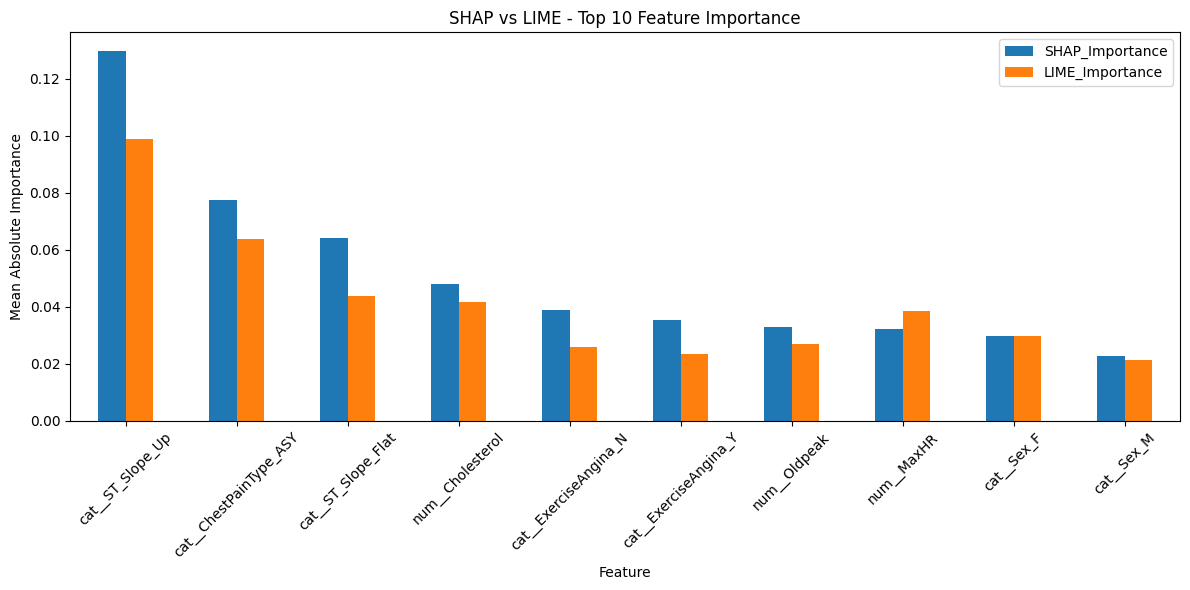

In [17]:
comparison.set_index("Feature")[
    ["SHAP_Importance", "LIME_Importance"]
].sort_values(
    "SHAP_Importance",
    ascending=False
).head(10).plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("SHAP vs LIME - Top 10 Feature Importance")
plt.ylabel("Mean Absolute Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

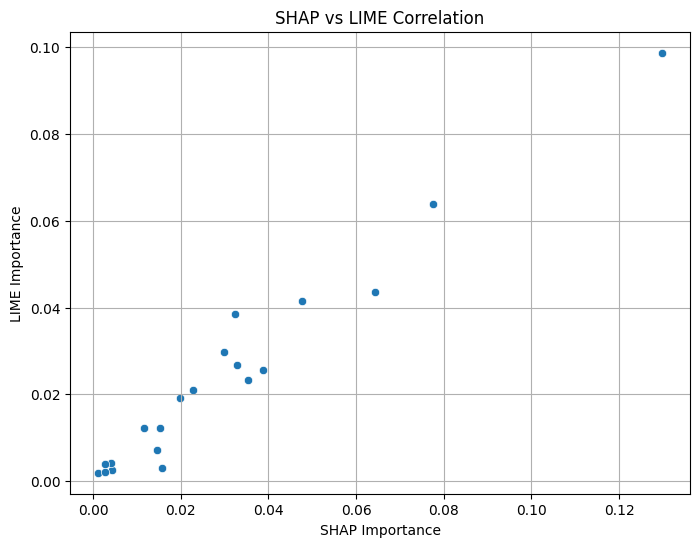

In [18]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=x,
    y=y_values
)

plt.title("SHAP vs LIME Correlation")
plt.xlabel("SHAP Importance")
plt.ylabel("LIME Importance")
plt.grid(True)
plt.show()

# LIME stability analysis

In [19]:
sample = np.asarray(X_test_processed[0]).ravel()

lime_runs = []

for run in range(10):

    exp = lime_explainer.explain_instance(
        data_row=sample,
        predict_fn=predict_function,
        num_features=len(feature_names),
        labels=(1,)
    )

    weights = dict(exp.as_map()[1])

    lime_runs.append([
        weights.get(j, 0)
        for j in range(len(feature_names))
    ])

lime_runs = np.array(lime_runs)

stability_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Contribution": np.mean(lime_runs, axis=0),
    "Standard_Deviation": np.std(lime_runs, axis=0)
})

print(stability_df.sort_values(
    "Standard_Deviation",
    ascending=False
))

                   Feature  Mean_Contribution  Standard_Deviation
9   cat__ChestPainType_ATA          -0.012016            0.002485
8   cat__ChestPainType_ASY           0.061237            0.002397
16   cat__ExerciseAngina_Y           0.023113            0.002359
12     cat__RestingECG_LVH           0.001064            0.002244
17      cat__ST_Slope_Down           0.001674            0.002196
10  cat__ChestPainType_NAP          -0.011819            0.002101
5             num__Oldpeak           0.028606            0.002026
19        cat__ST_Slope_Up          -0.099019            0.001993
14      cat__RestingECG_ST           0.003403            0.001965
13  cat__RestingECG_Normal          -0.003585            0.001861
11   cat__ChestPainType_TA          -0.000528            0.001761
3           num__FastingBS           0.017259            0.001709
6               cat__Sex_F          -0.031780            0.001560
0                 num__Age           0.006223            0.001534
2         